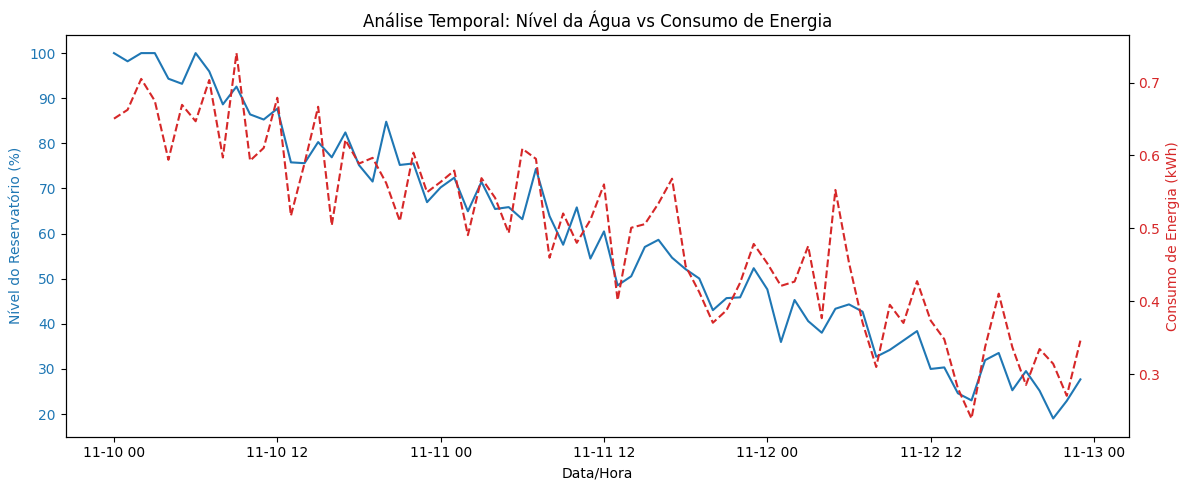

,data_hora,nivel_reservatorio_pct,vazao_l_min,consumo_energia_kwh
0,2026-11-10 00:00:00,100.000000,12.709672,0.650473
1,2026-11-10 01:00:00,98.181918,10.119764,0.662595
2,2026-11-10 02:00:00,100.000000,10.227328,0.704983
3,2026-11-10 03:00:00,100.000000,9.275410,0.674826
4,2026-11-10 04:00:00,94.322191,5.821972,0.594078


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Definir semente para reprodutibilidade
np.random.seed(42)

# 1. Gerar dados simulados (72 registros, como a ementa pede)
dias = 3
registros_por_dia = 24
n = dias * registros_por_dia

# Gerar datas
datas = pd.date_range(start='2026-11-10', periods=n, freq='h')

# Simular o comportamento da horta
# Nível da água cai ao longo do dia e é reposto (simulando a bomba ligando)
nivel_agua = np.linspace(100, 20, n) + np.random.normal(0, 5, n)
nivel_agua = np.clip(nivel_agua, 0, 100) # Mantém entre 0 e 100

# Vazão e consumo (com picos quando o nível está baixo)
vazao = np.random.uniform(5, 15, n) + (100 - nivel_agua) * 0.1
consumo = 0.2 + (nivel_agua / 100) * 0.5 + np.random.normal(0, 0.05, n)

# Criar DataFrame
df = pd.DataFrame({
    'data_hora': datas,
    'nivel_reservatorio_pct': nivel_agua,
    'vazao_l_min': vazao,
    'consumo_energia_kwh': consumo
})

# Salvar CSV (opcional, para entregar junto se quiser)
df.to_csv('dados_estacao.csv', index=False)

# 2. Análise Temporal (Gráficos)
fig, ax1 = plt.subplots(figsize=(12, 5))

color = 'tab:blue'
ax1.set_xlabel('Data/Hora')
ax1.set_ylabel('Nível do Reservatório (%)', color=color)
ax1.plot(df['data_hora'], df['nivel_reservatorio_pct'], color=color, label='Nível da Água')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Consumo de Energia (kWh)', color=color)
ax2.plot(df['data_hora'], df['consumo_energia_kwh'], color=color, linestyle='--', label='Consumo')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Análise Temporal: Nível da Água vs Consumo de Energia')
fig.tight_layout()
plt.show()

# Mostrar as primeiras linhas
df.head()

Coeficientes da reta: [-0.0049611   0.67724337]
MAE (Erro Médio Absoluto): 0.0378 kWh


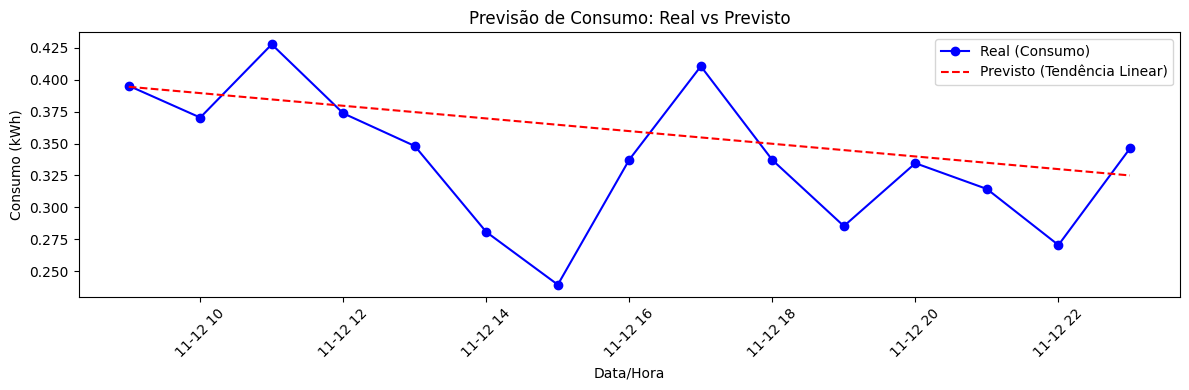

In [ ]:
from sklearn.metrics import mean_absolute_error

# 1. Separar treino e teste (80% / 20%)
tamanho_treino = int(len(df) * 0.8)
treino = df.iloc[:tamanho_treino]
teste = df.iloc[tamanho_treino:]

# 2. Criar a tendência linear (usando o índice do tempo como X)
# Vamos prever o consumo de energia
x_treino = np.arange(len(treino))
y_treino = treino['consumo_energia_kwh'].values

# np.polyfit encontra a reta (a*x + b)
coeficientes = np.polyfit(x_treino, y_treino, 1)

# 3. Fazer a previsão para o período de teste
x_teste = np.arange(len(treino), len(df))
previsao = np.polyval(coeficientes, x_teste)

# 4. Calcular o MAE (Mean Absolute Error)
real = teste['consumo_energia_kwh'].values
mae = mean_absolute_error(real, previsao)

print(f"Coeficientes da reta: {coeficientes}")
print(f"MAE (Erro Médio Absoluto): {mae:.4f} kWh")

# 5. Plotar o gráfico de Previsão vs Real
plt.figure(figsize=(12, 4))
plt.plot(teste['data_hora'], real, label='Real (Consumo)', color='blue', marker='o')
plt.plot(teste['data_hora'], previsao, label='Previsto (Tendência Linear)', color='red', linestyle='--')
plt.title('Previsão de Consumo: Real vs Previsto')
plt.xlabel('Data/Hora')
plt.ylabel('Consumo (kWh)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

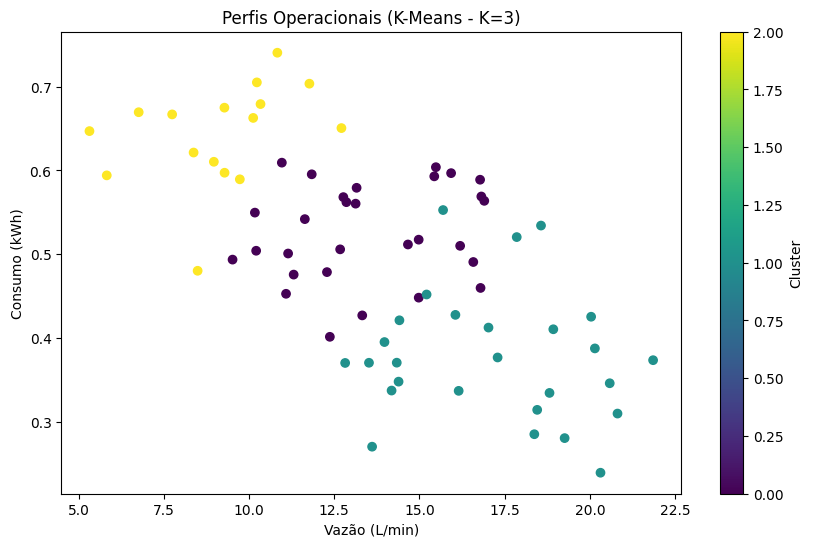

Média dos clusters:
         nivel_reservatorio_pct  vazao_l_min  consumo_energia_kwh  eficiencia
cluster                                                                      
0                     64.151273    13.514896             0.526177    0.039935
1                     36.044052    17.135599             0.377984    0.022639
2                     89.995796     9.108383             0.643214    0.073968

Arquivo previsao_estacao.json gerado com sucesso!


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import json

# 1. Feature Engineering (Criar novas características)
# Vamos criar uma feature de "eficiência": consumo por litro de água
df['eficiencia'] = df['consumo_energia_kwh'] / (df['vazao_l_min'] + 0.01) # +0.01 para evitar divisão por zero

# 2. Selecionar as features para o K-Means
features = df[['nivel_reservatorio_pct', 'vazao_l_min', 'eficiencia']]

# 3. Padronizar os dados (StandardScaler) - Obrigatório para o K-Means
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# 4. Aplicar o K-Means com K=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(features_scaled)

# 5. Visualizar os clusters
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df['vazao_l_min'], df['consumo_energia_kwh'], c=df['cluster'], cmap='viridis')
plt.title('Perfis Operacionais (K-Means - K=3)')
plt.xlabel('Vazão (L/min)')
plt.ylabel('Consumo (kWh)')
plt.colorbar(scatter, label='Cluster')
plt.show()

# 6. Mostrar a média de cada cluster
resumo_clusters = df.groupby('cluster')[['nivel_reservatorio_pct', 'vazao_l_min', 'consumo_energia_kwh', 'eficiencia']].mean()
print("Média dos clusters:")
print(resumo_clusters)

# 7. Gerar o JSON para a integração com o App
# Vamos pegar a previsão da próxima hora (o último valor) e o perfil de cada cluster
previsao_proxima_hora = previsao[-1] # Pega a última previsão do teste

dados_integracao = {
    "previsao_consumo_proxima_hora": round(float(previsao_proxima_hora), 4),
    "cluster_atual": int(df['cluster'].iloc[-1]),
    "descricao_cluster_atual": "Perfil " + str(int(df['cluster'].iloc[-1])),
    "metricas_clusters": resumo_clusters.to_dict()
}

# Salvar o JSON
with open('previsao_estacao.json', 'w') as f:
    json.dump(dados_integracao, f, indent=4)

print("\nArquivo previsao_estacao.json gerado com sucesso!")